In [1]:
import os
import numpy as np
import pandas as pd

# Create dataset directory
out_dir = "CH24_Manufacturing_Quality_Datasets"
os.makedirs(out_dir, exist_ok=True)

rng = np.random.default_rng(24024)
n = 1200

# 1. Production Data
batch_ids = [f"BF{i:05d}" for i in range(1, n + 1)]
lines = rng.choice(
    ["Line A", "Line B", "Line C", "Line D"],
    size=n,
    p=[0.24, 0.28, 0.26, 0.22],
)
shifts = rng.choice(["Morning", "Evening", "Night"], size=n, p=[0.38, 0.34, 0.28])
machines = rng.choice([f"M{i:02d}" for i in range(1, 31)], size=n)
quantities = rng.integers(80, 501, size=n)

production = pd.DataFrame({
    "batch": batch_ids,
    "line": lines,
    "shift": shifts,
    "quantity": quantities,
    "machine": machines,
})
# Intentionally add 20 duplicate rows for data quality checks
production = pd.concat([production, production.iloc[:20]], ignore_index=True)
production.to_csv(os.path.join(out_dir, "production.csv"), index=False)

# 2. Machine Master Data
machine_ids = [f"M{i:02d}" for i in range(1, 31)]
age_bands = rng.choice(
    ["0-2 years", "3-5 years", "6-8 years", "9+ years"],
    size=30,
    p=[0.25, 0.35, 0.25, 0.15],
)
operating_hours = np.clip(
    rng.normal(12000, 4500, size=30), 500, 26000
).astype(int)

machines_df = pd.DataFrame({
    "machine": machine_ids,
    "age_band": age_bands,
    "operating_hours": operating_hours,
})
machines_df.to_csv(os.path.join(out_dir, "machines.csv"), index=False)

# 3. Process Readings Data (with extreme values and missing values)
line_temp_effect = (
    pd.Series(lines)
    .map({"Line A": 0, "Line B": 3, "Line C": 6, "Line D": -2})
    .to_numpy()
)
temp = rng.normal(180 + line_temp_effect, 12, size=n)
pressure = rng.normal(70, 8, size=n)
speed = rng.normal(100, 10, size=n)

# Intentional extreme sensor values
temp[rng.choice(n, 3, replace=False)] = [350, 420, 20]
pressure[rng.choice(n, 2, replace=False)] = [180, -12]
speed[rng.choice(n, 2, replace=False)] = [220, -25]

# Missing process readings
for arr, count in [(temp, 35), (pressure, 30), (speed, 28)]:
    arr[rng.choice(n, count, replace=False)] = np.nan

process = pd.DataFrame({
    "batch": batch_ids,
    "temperature": np.round(temp, 2),
    "pressure": np.round(pressure, 2),
    "speed": np.round(speed, 2),
})
process.to_csv(os.path.join(out_dir, "process.csv"), index=False)

# 4. Materials Data (with unmatched batch IDs)
suppliers = rng.choice(
    ["NorthStar Materials", "PrimeChem", "AlloyWorks", "MetroSupply"], size=n
)
grades = rng.choice(
    ["Grade A", "Grade B", "Grade C"], size=n, p=[0.45, 0.35, 0.20]
)
lots = [f"LOT{i:04d}" for i in rng.integers(1, 301, size=n)]
material_batches = batch_ids.copy()
unmatched_indices = rng.choice(n, 12, replace=False)
for idx in unmatched_indices:
    material_batches[idx] = f"UNKNOWN{idx+1:04d}"

materials = pd.DataFrame({
    "batch": material_batches,
    "supplier": suppliers,
    "material_grade": grades,
    "lot": lots,
})
materials.to_csv(os.path.join(out_dir, "materials.csv"), index=False)

# 5. Inspection Data (with inconsistent defect category labels)
defect_counts = rng.integers(0, 6, size=n)
defect_types = []
for d in defect_counts:
    if d == 0:
        defect_types.append("None")
    else:
        defect_types.append(
            rng.choice([
                "Surface Scratch",
                "Dimensional Error",
                "Weld Defect",
                "Porosity",
            ])
        )

inspection = pd.DataFrame({
    "batch": batch_ids,
    "defect_type": defect_types,
    "defect_count": defect_counts,
    "quality_status": np.where(
        defect_counts == 0,
        "Pass",
        np.where(defect_counts < 4, "Rework", "Fail"),
    ),
})

# Introduce inconsistent case/whitespace labels
label_variants = {
    "Surface Scratch": [
        "surface scratch",
        "Surface scratch ",
        "SURFACE SCRATCH",
    ],
    "Dimensional Error": [
        "dimensional error",
        "Dimensional Error ",
        "DIMENSIONAL ERROR",
    ],
    "Weld Defect": ["weld defect", "Weld Defect ", "WELD DEFECT"],
    "Porosity": ["porosity", "Porosity ", "POROSITY"],
}
for i in rng.choice(n, 55, replace=False):
    orig = inspection.loc[i, "defect_type"]
    if orig in label_variants:
        inspection.loc[i, "defect_type"] = rng.choice(label_variants[orig])

inspection.to_csv(os.path.join(out_dir, "inspection.csv"), index=False)

print("All 5 datasets successfully generated inside folder:", out_dir)

All 5 datasets successfully generated inside folder: CH24_Manufacturing_Quality_Datasets


In [2]:
import pandas as pd

production = pd.read_csv("CH24_Manufacturing_Quality_Datasets/production.csv")
machines = pd.read_csv("CH24_Manufacturing_Quality_Datasets/machines.csv")
process = pd.read_csv("CH24_Manufacturing_Quality_Datasets/process.csv")
materials = pd.read_csv("CH24_Manufacturing_Quality_Datasets/materials.csv")
inspection = pd.read_csv("CH24_Manufacturing_Quality_Datasets/inspection.csv")

print("Production shape:", production.shape)
print("Machines shape:", machines.shape)
print("Process shape:", process.shape)
print("Materials shape:", materials.shape)
print("Inspection shape:", inspection.shape)

Production shape: (1220, 5)
Machines shape: (30, 3)
Process shape: (1200, 4)
Materials shape: (1200, 4)
Inspection shape: (1200, 4)


In [3]:
# --- 1. DATA QUALITY INSPECTION ---
print("Duplicate rows in production:", production.duplicated().sum())
print("\nMissing values in process:\n", process.isnull().sum())
print("\nUnique defect types before cleaning:\n", inspection["defect_type"].value_counts())

# --- 2. DATA CLEANING ---
# A. Remove duplicate rows from production
production_clean = production.drop_duplicates()

# B. Standardize defect type labels (fix case and trailing whitespace)
inspection_clean = inspection.copy()
inspection_clean["defect_type"] = (
    inspection_clean["defect_type"].str.strip().str.title()
)

# C. Handle extreme or missing values in process readings (e.g., replace negative values with NaN or drop/impute)
# Let's inspect rows with extreme readings first
print("\nProcess data shape before cleaning:", process.shape)

# --- 3. MERGING DATASETS ---
# Merge production with process, inspection, materials, and machines
df_merged = (
    production_clean.merge(process, on="batch", how="left")
    .merge(inspection_clean, on="batch", how="left")
    .merge(
        materials, on="batch", how="left", suffixes=("_prod", "_mat")
    )  # Outer/Left join handles unmatched batch lots
    .merge(machines, on="machine", how="left")
)

print("\nSuccessfully Merged DataFrame Shape:", df_merged.shape)
display(df_merged.head())

Duplicate rows in production: 20

Missing values in process:
 batch           0
temperature    35
pressure       30
speed          28
dtype: int64

Unique defect types before cleaning:
 defect_type
Dimensional Error     256
Weld Defect           253
Surface Scratch       230
Porosity              222
Surface scratch         6
Weld Defect             5
dimensional error       5
DIMENSIONAL ERROR       4
WELD DEFECT             4
POROSITY                4
Dimensional Error       4
SURFACE SCRATCH         3
porosity                3
surface scratch         3
Porosity                2
weld defect             2
Name: count, dtype: int64

Process data shape before cleaning: (1200, 4)

Successfully Merged DataFrame Shape: (1200, 16)


,batch,line,shift,quantity,machine,temperature,pressure,speed,defect_type,defect_count,quality_status,supplier,material_grade,lot,age_band,operating_hours
0,BF00001,Line B,Evening,186,M17,188.04,65.28,96.96,NaN,0,Pass,NorthStar Materials,Grade A,LOT0179,0-2 years,13574
1,BF00002,Line B,Evening,445,M19,169.64,71.63,109.68,Porosity,1,Rework,NorthStar Materials,Grade A,LOT0072,9+ years,8469
2,BF00003,Line D,Evening,478,M20,166.29,63.33,NaN,Porosity,2,Rework,MetroSupply,Grade B,LOT0059,9+ years,4006
3,BF00004,Line A,Morning,286,M08,200.33,71.16,105.61,Porosity,3,Rework,MetroSupply,Grade A,LOT0112,6-8 years,8436
4,BF00005,Line D,Evening,357,M18,194.38,60.99,97.65,Surface Scratch,5,Fail,PrimeChem,Grade A,LOT0045,0-2 years,9840


--- Defect Rate by Production Line ---


,line,total_quantity,total_defects,defect_rate
0,Line A,86736,739,0.008520
1,Line B,91887,830,0.009033
2,Line C,96052,787,0.008193
3,Line D,72763,630,0.008658


/tmp/ipykernel_1099/955382654.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


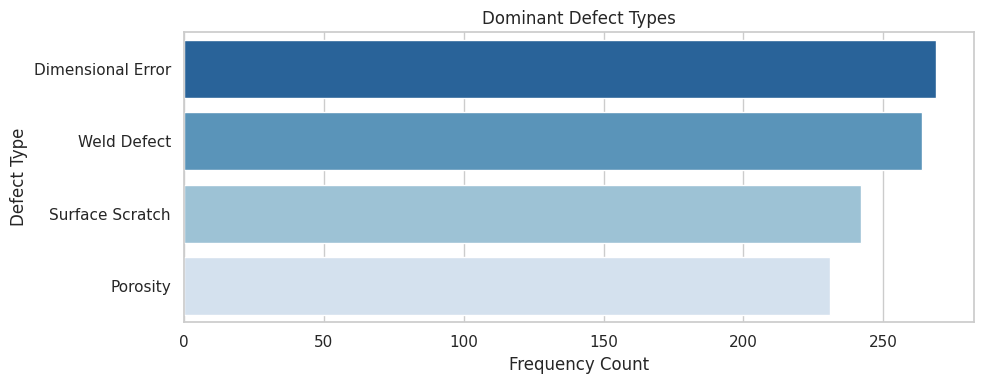


--- Defect Rate by Shift ---


,shift,total_quantity,total_defects,defect_rate
0,Evening,109712,958,0.008732
1,Morning,136387,1150,0.008432
2,Night,101339,878,0.008664



--- Defect Rate by Supplier ---


,supplier,total_quantity,total_defects,defect_rate
0,AlloyWorks,86825,793,0.009133
1,MetroSupply,86580,732,0.008455
2,NorthStar Materials,84675,741,0.008751
3,PrimeChem,86158,699,0.008113


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# --- A. DEFECT RATE BY PRODUCTION LINE ---
line_summary = (
    df_merged.groupby("line")
    .agg(
        total_quantity=("quantity", "sum"),
        total_defects=("defect_count", "sum"),
    )
    .reset_index()
)
line_summary["defect_rate"] = (
    line_summary["total_defects"] / line_summary["total_quantity"]
)
print("--- Defect Rate by Production Line ---")
display(line_summary)

# --- B. DOMINANT DEFECT TYPES (Bar Chart) ---
plt.figure(figsize=(10, 4))
valid_defects = df_merged[df_merged["defect_type"] != "None"]
sns.countplot(
    data=valid_defects,
    y="defect_type",
    order=valid_defects["defect_type"].value_counts().index,
    palette="Blues_r",
)
plt.title("Dominant Defect Types")
plt.xlabel("Frequency Count")
plt.ylabel("Defect Type")
plt.tight_layout()
plt.show()

# --- C. SHIFT COMPARISON ---
shift_summary = (
    df_merged.groupby("shift")
    .agg(
        total_quantity=("quantity", "sum"),
        total_defects=("defect_count", "sum"),
    )
    .reset_index()
)
shift_summary["defect_rate"] = (
    shift_summary["total_defects"] / shift_summary["total_quantity"]
)
print("\n--- Defect Rate by Shift ---")
display(shift_summary)

# --- D. SUPPLIER COMPARISON ---
supplier_summary = (
    df_merged.groupby("supplier")
    .agg(
        total_quantity=("quantity", "sum"),
        total_defects=("defect_count", "sum"),
    )
    .reset_index()
)
supplier_summary["defect_rate"] = (
    supplier_summary["total_defects"] / supplier_summary["total_quantity"]
)
print("\n--- Defect Rate by Supplier ---")
display(supplier_summary)

/tmp/ipykernel_1099/317385217.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1099/317385217.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1099/317385217.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


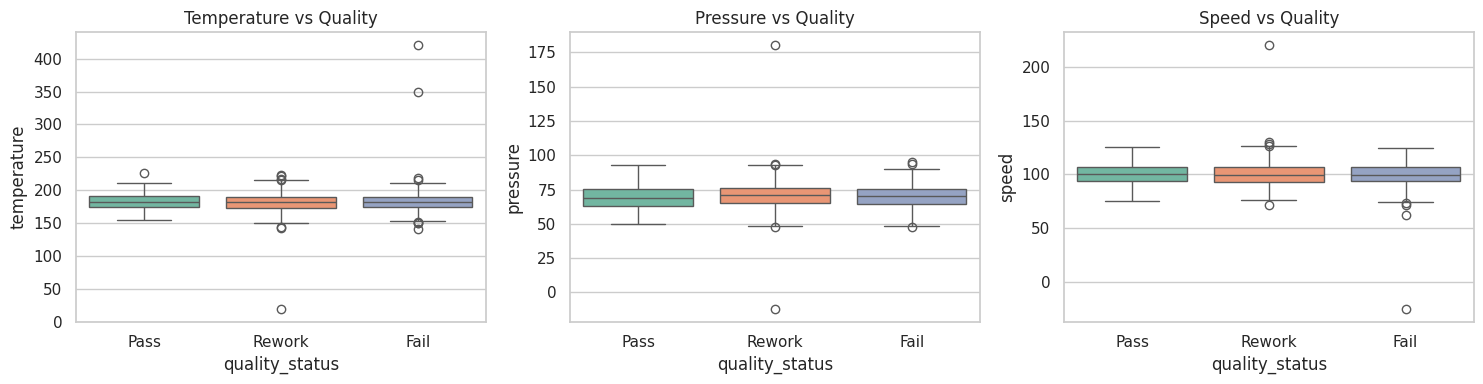

Engineered new features: temp_deviation, pressure_deviation, speed_deviation


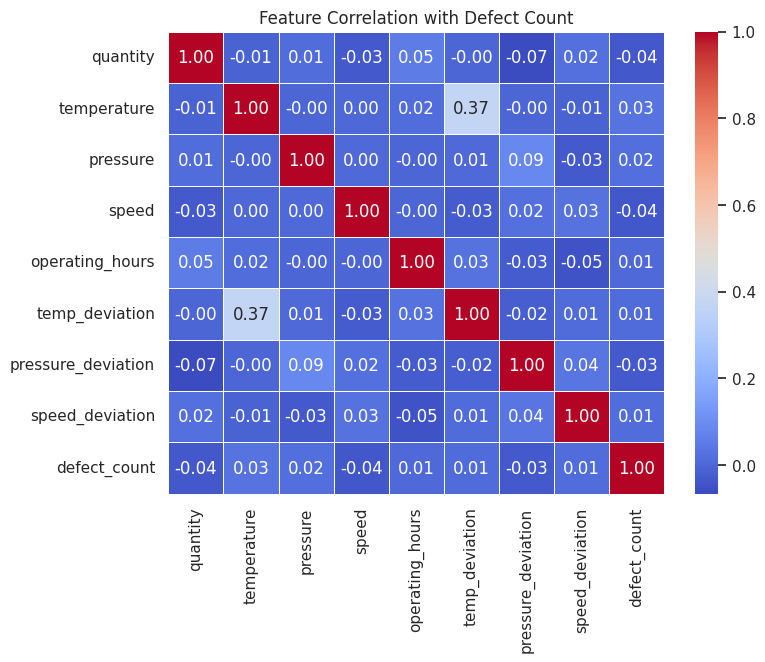

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# --- D. PROCESS VARIABLES VS QUALITY STATUS ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(
    data=df_merged, x="quality_status", y="temperature", ax=axes[0], palette="Set2"
)
axes[0].set_title("Temperature vs Quality")

sns.boxplot(
    data=df_merged, x="quality_status", y="pressure", ax=axes[1], palette="Set2"
)
axes[1].set_title("Pressure vs Quality")

sns.boxplot(
    data=df_merged, x="quality_status", y="speed", ax=axes[2], palette="Set2"
)
axes[2].set_title("Speed vs Quality")
plt.tight_layout()
plt.show()

# --- E. FEATURE ENGINEERING ---
# Create useful columns: Deviations from standard operating targets (Temp=180, Pressure=70, Speed=100)
df_merged["temp_deviation"] = np.abs(df_merged["temperature"] - 180)
df_merged["pressure_deviation"] = np.abs(df_merged["pressure"] - 70)
df_merged["speed_deviation"] = np.abs(df_merged["speed"] - 100)

# Machine workload feature (Interaction of operating hours and age band risk)
print("Engineered new features: temp_deviation, pressure_deviation, speed_deviation")

# --- F. FEATURE SELECTION & CORRELATION HEATMAP ---
numeric_cols = [
    "quantity",
    "temperature",
    "pressure",
    "speed",
    "operating_hours",
    "temp_deviation",
    "pressure_deviation",
    "speed_deviation",
    "defect_count",
]
corr_matrix = df_merged[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation with Defect Count")
plt.show()

In [6]:
# Export cleaned dataset for Excel analysis
df_merged.to_csv("PrimeForge_Cleaned_Manufacturing_Data.csv", index=False)
print(
    "File saved successfully! Look for 'PrimeForge_Cleaned_Manufacturing_Data.csv'"
    " in the left file panel to download."
)

File saved successfully! Look for 'PrimeForge_Cleaned_Manufacturing_Data.csv' in the left file panel to download.
